In [1]:
# plotting pdf for dice rolls
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random as rd

In [2]:
# rolling a dice 10000 times and getting it's output and plotting it's distribution
result = []
for i in range(10000):
    result.append(rd.randint(1, 6))

In [3]:
result[:6]

[5, 1, 3, 6, 4, 6]

In [4]:
ser = pd.Series(result)
ser.head(6)

0    5
1    1
2    3
3    6
4    4
5    6
dtype: int64

In [5]:
ser.value_counts()

5    1721
3    1704
2    1699
6    1682
4    1628
1    1566
Name: count, dtype: int64

In [6]:
prob = (ser.value_counts()) / 10000
prob = prob.sort_index()
prob

1    0.1566
2    0.1699
3    0.1704
4    0.1628
5    0.1721
6    0.1682
Name: count, dtype: float64

In [7]:
prob = prob.reset_index()
prob = prob.rename(columns = {'index' : 'number', 'count' : 'probability'})
prob

,number,probability
0,1,0.1566
1,2,0.1699
2,3,0.1704
3,4,0.1628
4,5,0.1721
5,6,0.1682


<Axes: xlabel='number', ylabel='probability'>

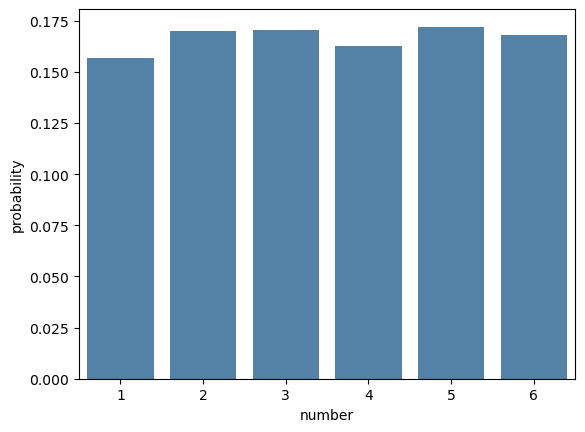

In [8]:
sns.barplot(data = prob, x = 'number', y = 'probability', color = 'steelblue')

In [9]:
# now rolling 2 dices for 10000 times and summing them, and plotting their distribution
sum = []
for i in range(10000):
    a = rd.randint(1, 6)
    b = rd.randint(1, 6)
    sum.append(a+b)

In [10]:
sum_ser = pd.Series(sum)

In [11]:
sum_ser.value_counts()

7     1702
8     1435
6     1347
9     1127
5     1119
10     848
4      793
11     560
3      550
2      272
12     247
Name: count, dtype: int64

In [12]:
sum_ser = (sum_ser.value_counts()) / 10000
sum_ser

7     0.1702
8     0.1435
6     0.1347
9     0.1127
5     0.1119
10    0.0848
4     0.0793
11    0.0560
3     0.0550
2     0.0272
12    0.0247
Name: count, dtype: float64

In [13]:
sum_ser = sum_ser.reset_index().rename(columns = {'index': 'sum', 'count' : 'probability'})
sum_ser

,sum,probability
0,7,0.1702
1,8,0.1435
2,6,0.1347
3,9,0.1127
4,5,0.1119
5,10,0.0848
6,4,0.0793
7,11,0.0560
8,3,0.0550
9,2,0.0272


<Axes: xlabel='sum', ylabel='probability'>

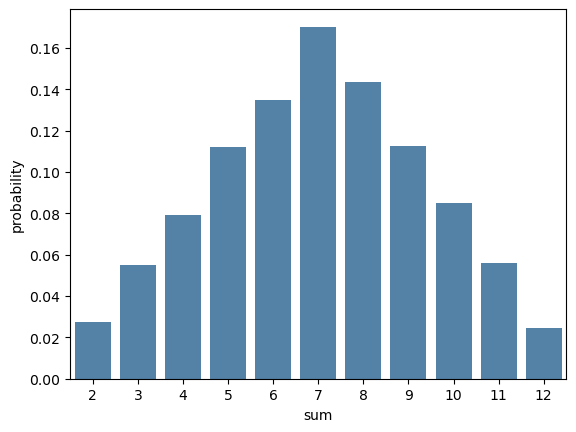

In [14]:
sns.barplot(data = sum_ser, x = 'sum', y = 'probability', color = 'steelblue')

In [15]:
# now plotting cummulative distribution function foir 1st and 2nd one
prob

,number,probability
0,1,0.1566
1,2,0.1699
2,3,0.1704
3,4,0.1628
4,5,0.1721
5,6,0.1682


In [16]:
prob['cummulative_probability'] = np.cumsum(prob['probability'])
prob

,number,probability,cummulative_probability
0,1,0.1566,0.1566
1,2,0.1699,0.3265
2,3,0.1704,0.4969
3,4,0.1628,0.6597
4,5,0.1721,0.8318
5,6,0.1682,1.0000


<Axes: xlabel='number', ylabel='cummulative_probability'>

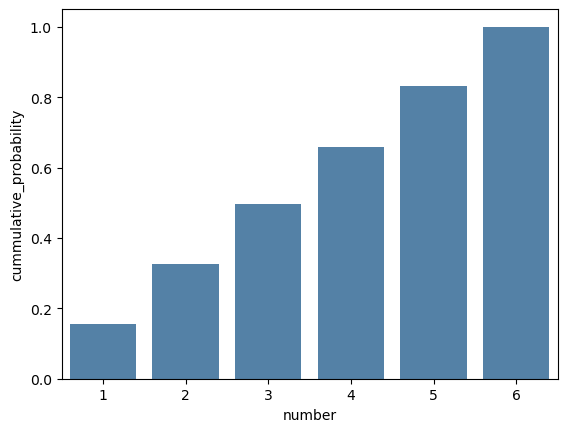

In [17]:
sns.barplot(data = prob, x = 'number', y = 'cummulative_probability', color = 'steelblue')

In [18]:
# for 2nd one
sum_ser.set_index('sum', inplace = True)
sum_ser

,probability
sum,
7,0.1702
8,0.1435
6,0.1347
9,0.1127
5,0.1119
10,0.0848
4,0.0793
11,0.0560
3,0.0550


In [19]:
sum_ser.sort_index(inplace = True)
sum_ser

,probability
sum,
2,0.0272
3,0.0550
4,0.0793
5,0.1119
6,0.1347
7,0.1702
8,0.1435
9,0.1127
10,0.0848


In [20]:
s = np.cumsum(sum_ser)
s

,probability
sum,
2,0.0272
3,0.0822
4,0.1615
5,0.2734
6,0.4081
7,0.5783
8,0.7218
9,0.8345
10,0.9193


<Axes: xlabel='sum'>

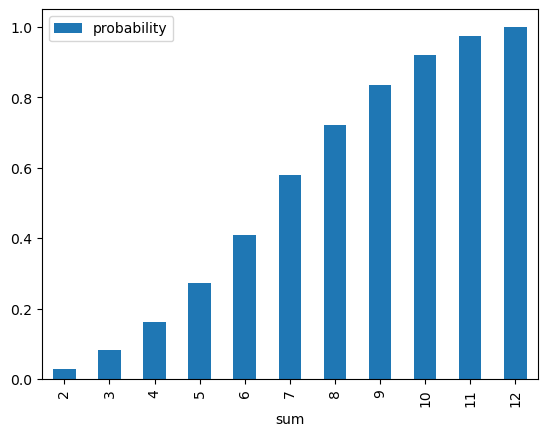

In [21]:
s.plot(kind = 'bar')

In [22]:
# now doing parametric density estimation
# getting 1000 samples from a normal distribution of mean 50 and std as 5
samples = np.random.normal(loc = 50, scale = 5, size = 1000)
samples

array([54.24316814, 51.58867574, 43.34981938, 54.04527675, 47.65178062,
       46.79240119, 55.02720182, 60.50684221, 45.26627384, 47.01838025,
       53.04533951, 55.33275339, 44.87836648, 49.56537658, 52.84931101,
       48.59335214, 54.25231309, 34.96070551, 42.80393524, 46.77283074,
       48.5296563 , 54.88577446, 55.8523739 , 52.338364  , 56.1157972 ,
       55.0894677 , 45.74510486, 51.78243561, 50.93656188, 47.19780941,
       50.41346119, 44.45256388, 44.17947652, 62.20360674, 57.23117504,
       57.14489391, 49.39321891, 44.41305252, 50.56040752, 49.40787443,
       48.91592372, 56.08937268, 52.06132859, 41.06072259, 46.49997759,
       53.7334518 , 51.16158822, 50.22980143, 51.36083022, 52.82285321,
       54.58128999, 46.6889626 , 47.36897466, 47.65247791, 55.26763694,
       42.73381059, 51.95485386, 48.27952039, 57.43177422, 46.93885186,
       50.313207  , 49.80951485, 46.15739377, 50.54397448, 49.96960336,
       48.87593096, 53.1981635 , 49.4206012 , 50.3398936 , 48.16

C:\Users\gpava\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: ylabel='Count'>

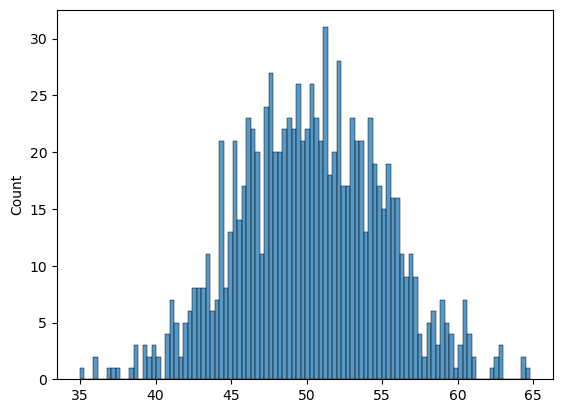

In [45]:
#plotting the histogram of the aboe data to understand it's distribution roughly
sns.histplot(data = samples, bins = 100)

In [24]:
# now calculating it's mean and std
sample_mean = np.mean(samples)
sample_mean

50.254518198283684

In [25]:
sample_std = np.std(samples)
sample_std

4.834912141324741

In [26]:
# now fitting a normal distribution with the above mean and std
from scipy.stats import norm
dist = norm(sample_mean, sample_std)
dist

In [27]:
# we have a normal object, now generating values and their proabbility density values with the samples get from above
# meaning we already made a distribution with the sample mean and sample std, now we are just taking some values and their pd values from above normal
values = np.linspace(samples.min(), samples.max(), 1000)
values

array([34.96070551, 34.99059837, 35.02049124, 35.05038411, 35.08027698,
       35.11016984, 35.14006271, 35.16995558, 35.19984844, 35.22974131,
       35.25963418, 35.28952705, 35.31941991, 35.34931278, 35.37920565,
       35.40909852, 35.43899138, 35.46888425, 35.49877712, 35.52866999,
       35.55856285, 35.58845572, 35.61834859, 35.64824145, 35.67813432,
       35.70802719, 35.73792006, 35.76781292, 35.79770579, 35.82759866,
       35.85749153, 35.88738439, 35.91727726, 35.94717013, 35.977063  ,
       36.00695586, 36.03684873, 36.0667416 , 36.09663446, 36.12652733,
       36.1564202 , 36.18631307, 36.21620593, 36.2460988 , 36.27599167,
       36.30588454, 36.3357774 , 36.36567027, 36.39556314, 36.425456  ,
       36.45534887, 36.48524174, 36.51513461, 36.54502747, 36.57492034,
       36.60481321, 36.63470608, 36.66459894, 36.69449181, 36.72438468,
       36.75427755, 36.78417041, 36.81406328, 36.84395615, 36.87384901,
       36.90374188, 36.93363475, 36.96352762, 36.99342048, 37.02

In [28]:
prob_density = [dist.pdf(value) for value in values]
prob_density

[0.0005543408631230617,
 0.00056527810883552,
 0.000576409114197115,
 0.000587736835220276,
 0.0005992642632871226,
 0.0006109944253827024,
 0.0006229303843259152,
 0.0006350752389980597,
 0.0006474321245688716,
 0.0006600042127199996,
 0.00067279471186576,
 0.0006858068673711071,
 0.0006990439617667056,
 0.000712509314960971,
 0.0007262062844490337,
 0.0007401382655184431,
 0.0007543086914515602,
 0.0007687210337244855,
 0.000783378802202459,
 0.0007982855453315629,
 0.0008134448503266528,
 0.0008288603433553878,
 0.0008445356897182305,
 0.0008604745940243401,
 0.000876680800363188,
 0.0008931580924718037,
 0.0009099102938975162,
 0.000926941268156111,
 0.0009442549188852058,
 0.0009618551899927813,
 0.000979746065800726,
 0.00099793157118323,
 0.0010164157716999868,
 0.0010352027737239745,
 0.0010542967245637629,
 0.001073701812580157,
 0.0010934222672971266,
 0.0011134623595067845,
 0.0011338264013683707,
 0.0011545187465010684,
 0.0011755437900704976,
 0.0011969059688688225,
 0.001

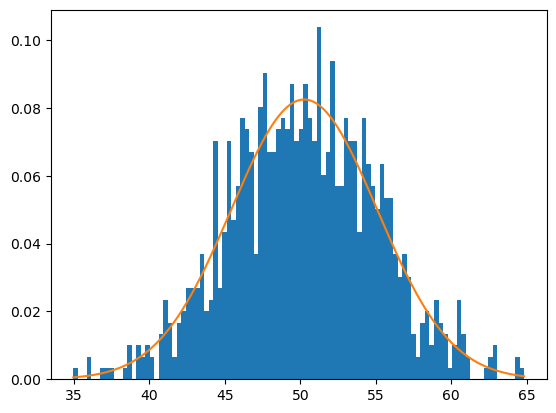

In [29]:
plt.hist(samples, bins = 100, density = True)
plt.plot(values, prob_density)

In [30]:
# the same above plot can be done diretly by using below without getting samplesl then making normal like that, here directly kde is used 
samples = pd.Series(samples)
samples

0      54.243168
1      51.588676
2      43.349819
3      54.045277
4      47.651781
         ...    
995    50.339164
996    57.282893
997    54.255876
998    47.589805
999    60.273734
Length: 1000, dtype: float64

In [31]:
samples.replace([np.inf, -np.inf], np.nan, inplace = True)
samples = samples.dropna()

C:\Users\gpava\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


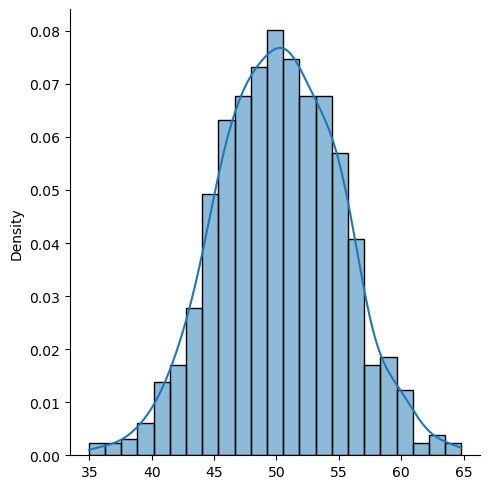

In [50]:
sns.displot(samples, kde = True, stat = 'density')

In [33]:
# kernel density estimation
# generating 2 different samples
sample1 = np.random.normal(loc = 20, scale = 5, size = 300)
sample2 = np.random.normal(loc = 40, scale = 5, size = 700)

In [34]:
sample = np.hstack((sample1, sample2))
sample

array([18.22883723, 13.08611821, 19.77095328, 20.74613106, 29.46720286,
       19.19367118, 20.0978412 , 20.30594513, 12.44323846, 20.67699351,
       17.69704685, 28.04227531, 20.7695246 , 20.6619385 , 25.71917177,
       11.6094219 , 22.89693547, 19.52286068, 16.47142161, 17.0512737 ,
       19.54493644, 16.69895942, 29.00314182, 24.4367687 , 20.11678446,
       15.83795369, 18.30144845, 27.84741156, 23.60482293, 18.11874072,
       22.11698145, 16.45762342, 17.89522551, 21.51986319, 30.49078551,
       21.69718767, 27.22145547, 20.39849107,  8.68109818, 18.71097531,
       29.58579932, 25.47500576, 21.63003241, 20.40325076, 19.64344063,
       23.27211459, 17.83123423, 18.81438971, 18.28850256, 22.07895375,
        9.72602452, 23.0725272 , 17.24912672, 21.67234284, 13.2231353 ,
       14.39534551, 21.72478173, 22.87194095,  9.96030501, 19.39169801,
       18.16433325, 21.14904636,  8.51945826, 26.98058799, 16.97208439,
       28.56636844, 20.9649808 , 13.6025375 , 20.81763399, 19.24

(array([ 1.,  0.,  0.,  0.,  0.,  1.,  4.,  1.,  4.,  7.,  8., 13., 10.,
        25., 19., 31., 22., 27., 20., 26., 21.,  9., 20., 12.,  9., 17.,
        17., 18., 19., 29., 44., 47., 51., 51., 71., 65., 63., 49., 53.,
        31., 23., 13., 18.,  8.,  8.,  5.,  5.,  1.,  3.,  1.]),
 array([ 1.01827024,  2.12894413,  3.23961802,  4.3502919 ,  5.46096579,
         6.57163968,  7.68231356,  8.79298745,  9.90366134, 11.01433522,
        12.12500911, 13.235683  , 14.34635689, 15.45703077, 16.56770466,
        17.67837855, 18.78905243, 19.89972632, 21.01040021, 22.12107409,
        23.23174798, 24.34242187, 25.45309576, 26.56376964, 27.67444353,
        28.78511742, 29.8957913 , 31.00646519, 32.11713908, 33.22781296,
        34.33848685, 35.44916074, 36.55983463, 37.67050851, 38.7811824 ,
        39.89185629, 41.00253017, 42.11320406, 43.22387795, 44.33455183,
        45.44522572, 46.55589961, 47.6665735 , 48.77724738, 49.88792127,
        50.99859516, 52.10926904, 53.21994293, 54.33061682,

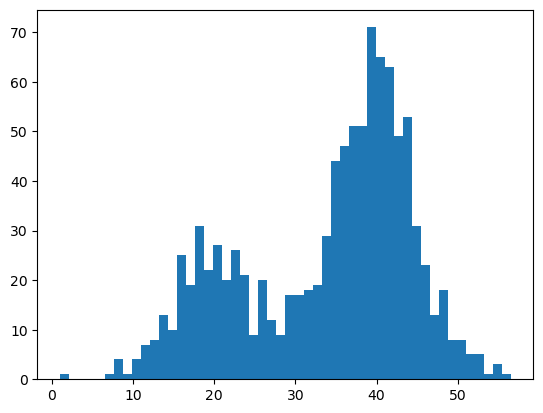

In [35]:
plt.hist(sample, bins = 50)

In [36]:
# now doing kernel estiamtion for above sample
from sklearn.neighbors import KernelDensity
model = KernelDensity(bandwidth = 3, kernel = 'gaussian')
sample = sample.reshape(len(sample),1)
model.fit(sample)

KernelDensity(bandwidth=3)

In [54]:
# now plotting the new pdf with above kde one
values = np.linspace(sample.min(), sample.max(), 1000)
values = values.reshape(len(values), 1)

In [55]:
probabilities = model.score_samples(values)
probabilities = np.exp(probabilities)

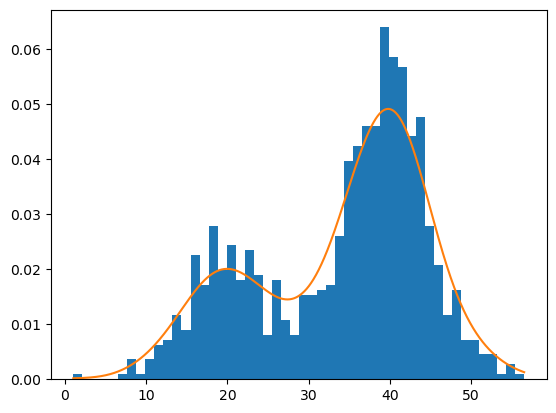

In [56]:
plt.hist(sample, bins = 50, density = True)
plt.plot(values, probabilities)

C:\Users\gpava\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: ylabel='Density'>

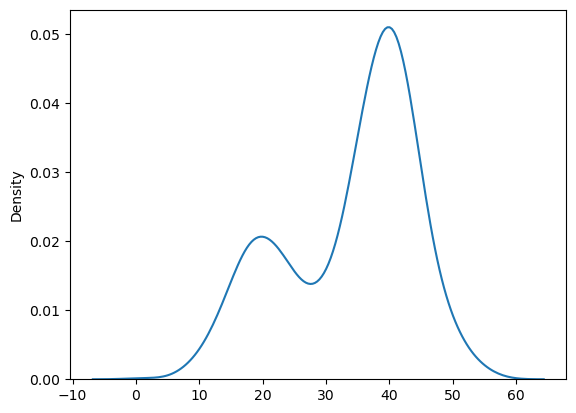

In [57]:
# all can be done by using this below
sns.kdeplot(sample.reshape(1000), bw_adjust = 1)